Оцінювання наявності даної роботи буде враховувати як наявність самих візуалізацій (вони можуть незначно відрізнятися від прикладів, але повинні змістовно відображати суть задачі) та опис отриманих вами результатів. При наявності ЛИШЕ візуалізацій без роз'яснень, завдання не буде зараховане за наявне.

Під час виконання вам дозволено користуватися будь-якими зручними для вас Python бібліотеками для візуалізації.

# I. Receiving Data.

In [89]:
# cell for imports. All imports must go here.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

1. (2б) Для виконання цієї лабораторної роботи Вам необхідно скористатися вибіркою titanic ([train.csv](https://www.kaggle.com/c/titanic/data?select=train.csv)). Зчитайте його та збережіть його у змінну, щоб у подальшому її використати для візуалізацій. Виведіть інформацію про кожну колонку, її індекс, тип та кількість непропущених значень та перші кілька рядків датафрейму.


In [90]:
df = pd.read_csv("sample_data/train.csv")

In [ ]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# IІ. Data Visualization.

2. (10б) Створіть pie chart, який би показував співвідношення виживших до загиблих.

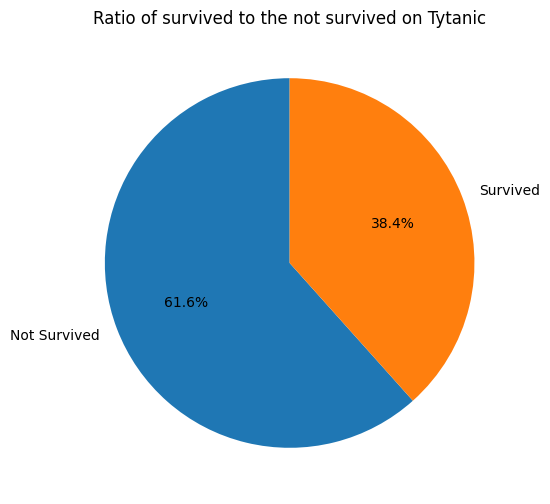

In [92]:
survived_counts = df['Survived'].value_counts()
labels = ['Not Survived', 'Survived']
plt.figure(figsize=(6,6))
plt.pie(survived_counts, labels = labels, autopct='%1.1f%%', startangle = 90)
plt.title('Ratio of survived to the not survived on Tytanic')
plt.show()

Отримано pie chart відношення виживших до загиблих на Титаніку (заголовок), де білий фон має розмір (6,6) є підписи секторів survived та not survived, додано відсоткове відображення даних на графіку та трохи повернено його для кращого вигляду.

На графіку видно що трохи більше половили людей на борту загинули



3. (20б) Створіть bar chart, який би показував співвідношення загиблих до виживших для кожної статі. Для groupby використовуйте атрибут as_index=False.


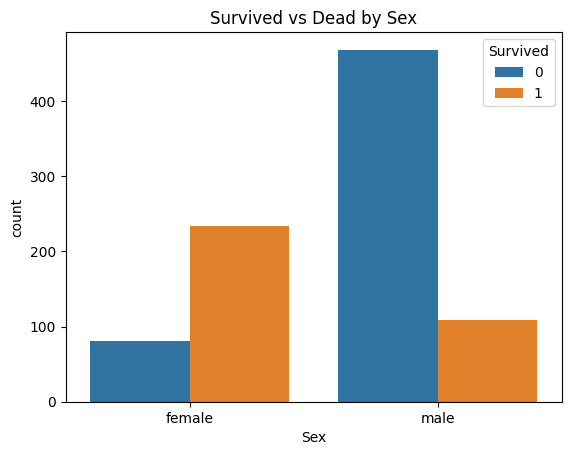

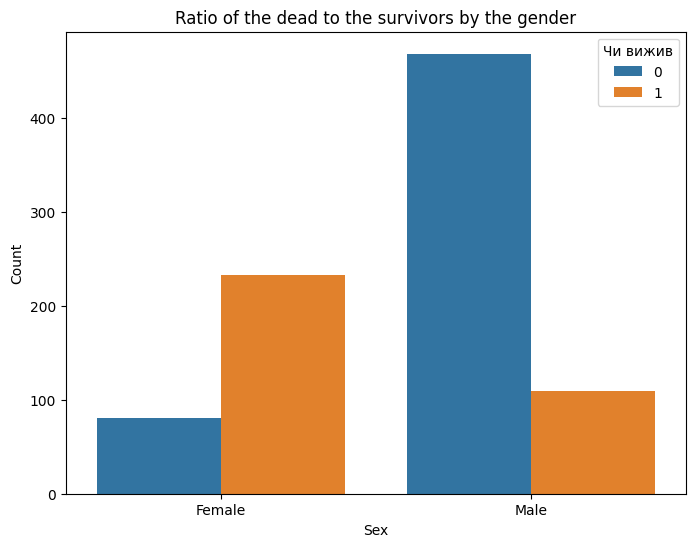

In [ ]:
gender_survival = df.groupby(['Sex','Survived'], as_index=False)['PassengerId'].count()
gender_survival.rename(columns={'PassengerId':'Count'}, inplace=True)

plt.figure(figsize=(8,6))
import seaborn as sns
sns.barplot(x='Sex',y='Count', hue='Survived', data=gender_survival)
plt.title('Ratio of the dead to the survivors by the gender')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.xticks(ticks=[0,1], labels=['Female','Male'])
plt.legend(title='Чи вижив')
plt.show()

Спочатку для отримання кращої візуалізації я зрупувала дані по статі і по тому чи вижила людина, далі перейменувала одну з колонок на Count. Далі створила білий фон розміром (8,6) та застосувала sns.barplot, де вказала що на осі Х буде позначено стать, а по Y відображатиметься кількість людей; додала назву графіку, підписала вісі як Count та Sex, підписала оці позначки внизу, та додала легенду графіка з підписом чи вижив

Графік показує що жінок вижило набагато більше ніж чоловіків, при тому що чоловіків пливло в рази більше, взагалі можна зробити висновок, що відсотків 60-70 жінок вижило, в той самий час вижило близько 10-20 відсотків чоловіків

4. (20б) Відобразіть кількість пропущених значень в датасеті по кожній із змінних.

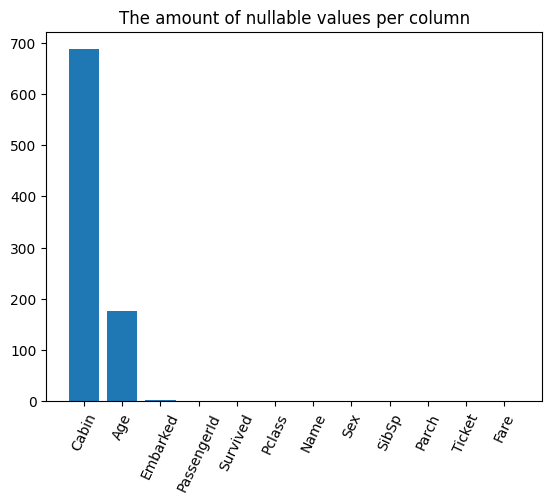

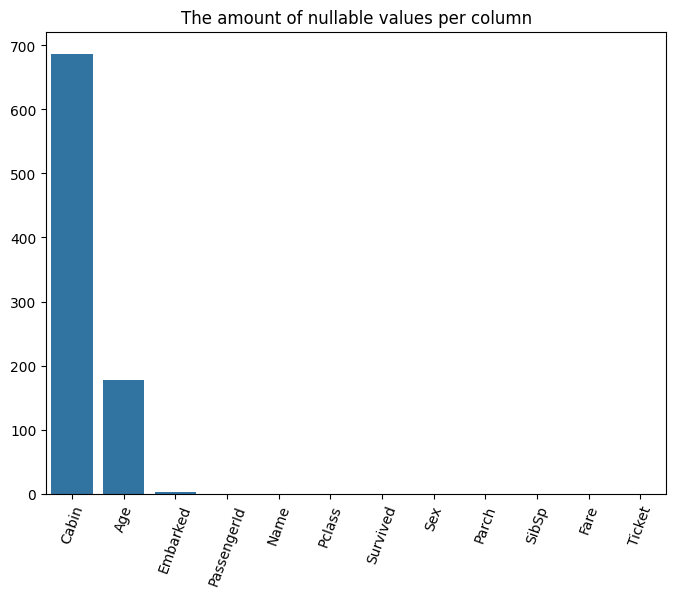

In [ ]:
nullable_amount = df.isna().sum().reset_index()
nullable_amount.columns = ['Column', 'Count']
nullable_amount = nullable_amount.sort_values(by='Count', ascending=False)
plt.figure(figsize=(8,6))
import seaborn as sns
sns.barplot(x='Column', y='Count', data=nullable_amount)
plt.title('The amount of nullable values per column')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=70)
plt.show()


Спочатку знайшла те що треба було відображати та посортувала за кількістю порожніх значень за спаданням. Далі задала розмір графіку, в barplot задала що саме в мене буде відображатись по вісі Х, а що по вісі Y. Додала загаловок графіку, задала порожні значення на підписах кожної з вісей і трохи повернула підписи колонок знизу для читабельності

Графік показує що найбільше нульових значень в колонці cabin, далі йде Age, а після нього Embarkened. У всіх інших колонках немає нульових значень.

5. (10б) Побудуйте наступний графік, дайте йому назву та опишіть, що власне на них відображається.

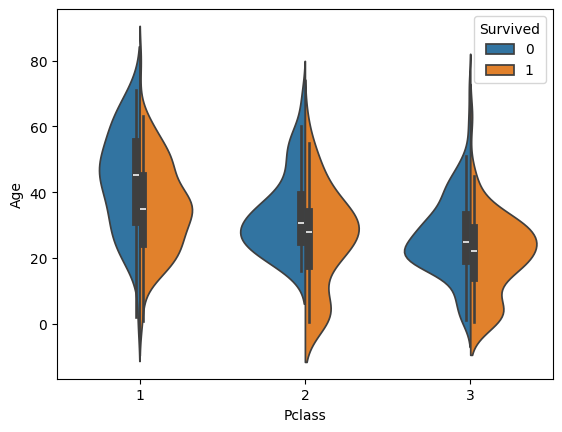

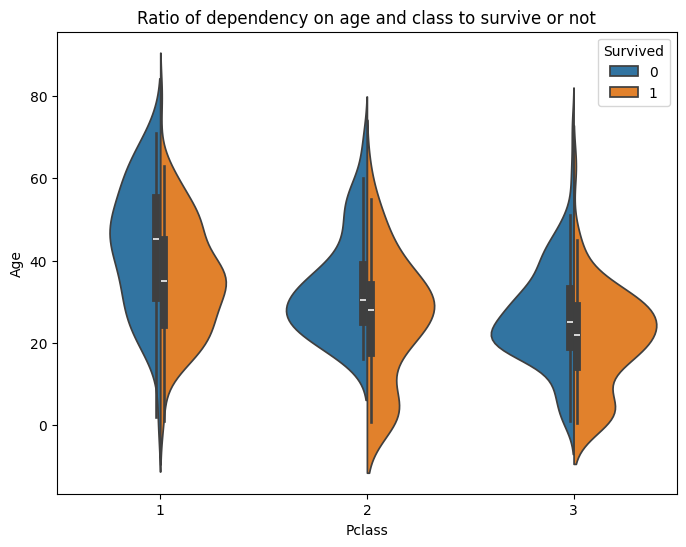

In [ ]:
age_and_class = df.groupby(['Age','Pclass'], as_index = False)['PassengerId'].count()
import seaborn as sns
plt.figure(figsize=(8,6))
sns.violinplot(
    x='Pclass',
    y='Age',
    hue='Survived',
    data=df,
    split=True
)
plt.title('Ratio of dependency on age and class to survive or not')
plt.xlabel('Pclass')
plt.ylabel('Age')

plt.show()


На діаграмі типу violin plot відображається залежність смертності від віку та класу пасажирів. Я побудувала її спочатку отримавши необхідні дані для демонстрації, далі за допомогою seaborn позначила що позначатимуть вісі, задала по чому буде розділення(ну і відповідно додала саме розділення). Ну і в кінці додала підписи вісей та назву діаграми


З цієї діаграми можна побачити. що перший клас найбільше обирали люди віком від 30 до 50 років, з них померло найбільше людей віком близько 45-50, а вижило найбільше тих, кому близько 40-а років.
Щодо другого класу, то його обирали здебільшого люди 20-40 років, з них найбільше і вижило, і померло людей віком близько 30 років
Третій клас обирали люди приблизно такоко ж віку, що й другий, але найбільше і вижило, і померло людей віком близько 22-25 років.

6. (13б) Побудуйте графік розподілу частот по віку пасажирів.


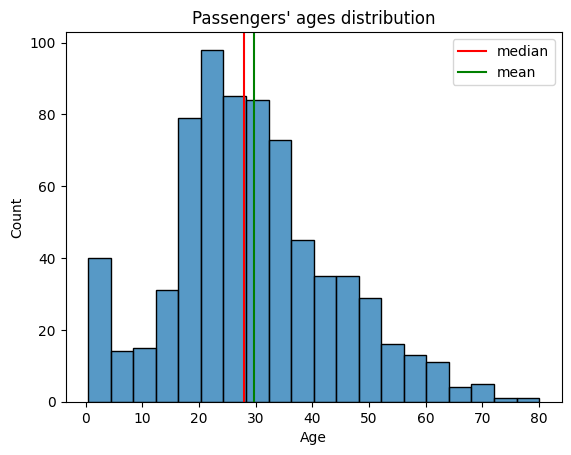

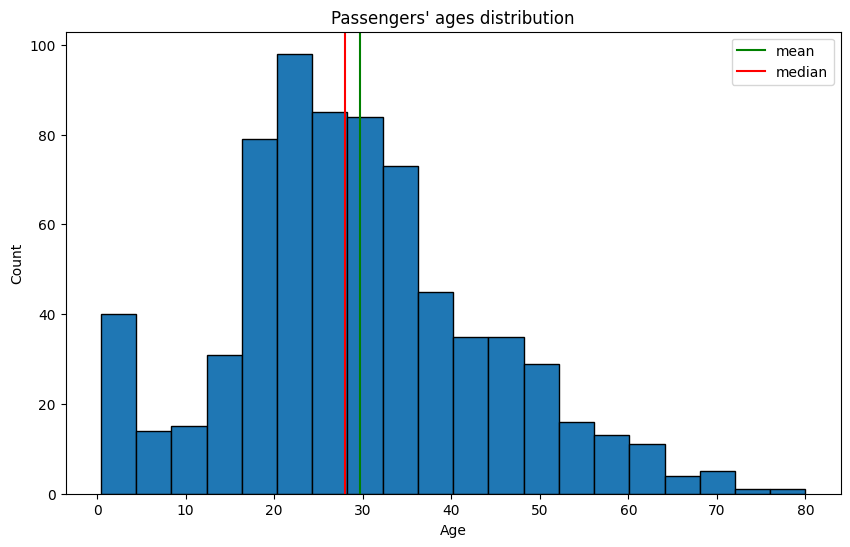

In [ ]:
ages = df['Age'].dropna()

mean_age = np.mean(ages)
median_age = np.median(ages)

plt.figure(figsize=(10, 6))
plt.hist(ages, bins=20, edgecolor='black')

plt.axvline(mean_age, color='green', linestyle='-', label='mean')
plt.axvline(median_age, color='red', linestyle='-', label='median')

plt.title("Passengers' ages distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.legend()
plt.show()

Спочатку створила сам датафрейм та написала як обраховувати медіану та середнє значення, далі задала розмір графіку, далі задала вигляд гістограми та прописала як саме має виглядати медіана та середнє значення. Дописала назву діаграми та вісей.

Найбільше людей було віком 20-25 років, а найменше - віком 70-80 років. Середнє значення - 30 років, а медіана - десь 28.

7. (25б) Поставте бізнес-питання до даних. Дайте на нього відповідь за допомогою візуалізацій. Прокоментуйте отриману відповідь.

Наскільки стать людини впливає на її класс поїздки

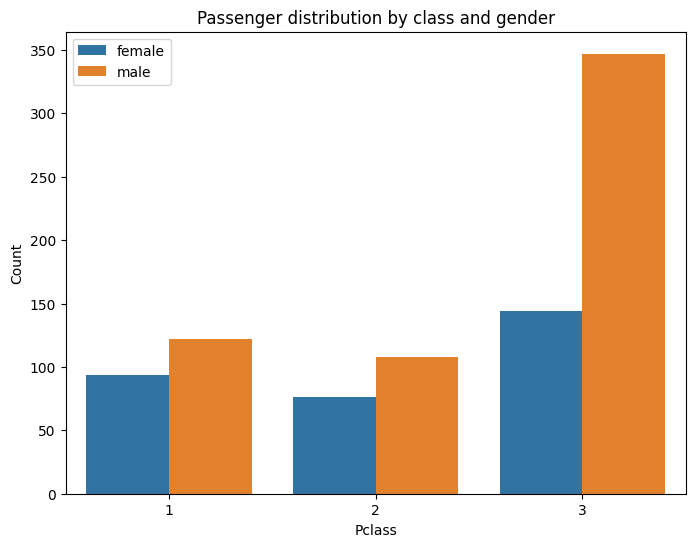

In [91]:
class_dependance = df.groupby(['Sex','Pclass']).size().reset_index(name='Count')
plt.figure(figsize=(8,6))
import seaborn as sns
sns.barplot(x='Pclass',y='Count', hue='Sex', data=class_dependance)
plt.title('Passenger distribution by class and gender')
plt.xlabel('Pclass')
plt.ylabel('Count')

plt.legend()
plt.show()

На даному графіку видно, що перший та другий класи чоловіки та жінки брали приблизно однаково, а 3-тім класом набагато більше пливли чоловіки.

# Вітаю! Ви велика(ий) молодець, що впоралась(вся). Похваліть себе та побалуйте чимось приємним. Я Вами пишаюся.

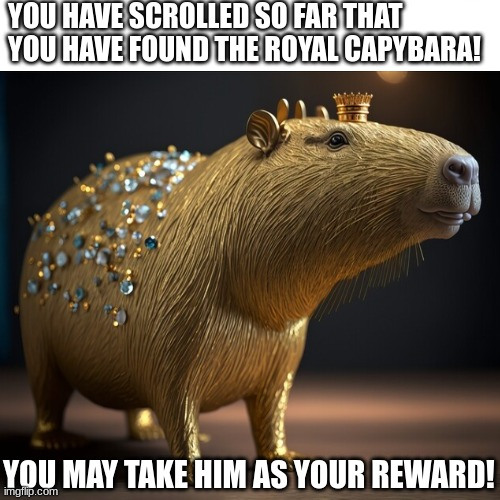